# 세 모델 앙상블 — ResNet18 + EfficientNet-B0 + ConvNeXt-Tiny

이미 학습해 둔 체크포인트 3개를 불러와서 **각 모델의 예측 확률(softmax)을 평균**하는 앙상블입니다(soft voting). **재학습은 없습니다.**

- 데이터 전처리와 train/val/test 분할(SEED=1414)은 개별 학습 노트북과 완전히 같습니다. test 세트도 동일한 5,104장입니다.
- 모든 모델에 TTA(8방향 평균)를 적용합니다.
- 어떤 조합을 쓸지는 **val 세트로 고르고**, test는 마지막에 보고만 합니다. test로 고르면 성능이 실제보다 좋게 보이기 때문입니다.

In [1]:
import os, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision import models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, confusion_matrix, accuracy_score

SEED = 1414
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASS_NAMES = ['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Random', 'Scratch', 'Near-full']
NUM_CLASSES = len(CLASS_NAMES)
IMG_SIZE, BATCH_SIZE = 96, 256

CKPTS = {
    "resnet18":        "outputs/resnet18_best.pth",
    "efficientnet_b0": "outputs/efficientnet_b0_best.pth",
    "convnext_tiny":   "outputs/convnext_tiny_best.pth",
}
print("device:", DEVICE)

device: cuda


## 1. 데이터 (개별 학습 노트북과 동일한 전처리 / 분할)

In [2]:
df = pd.read_pickle("../wb_withpattern.pkl")[['waferMap', 'failureNum']].reset_index(drop=True)
y = df['failureNum'].astype(int).values

LUT = np.array([0, 128, 255], dtype=np.uint8)
def preprocess(wmap, size=IMG_SIZE):
    img = LUT[np.clip(np.asarray(wmap, dtype=np.uint8), 0, 2)]
    return np.asarray(Image.fromarray(img).resize((size, size), Image.NEAREST))
X = np.stack([preprocess(m) for m in tqdm(df['waferMap'], desc="resize")])

idx = np.arange(len(y))
idx_trval, idx_test = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
idx_train, idx_val  = train_test_split(idx_trval, test_size=0.1, stratify=y[idx_trval], random_state=SEED)

def make_loader(ids):
    return DataLoader(TensorDataset(torch.from_numpy(X[ids]), torch.from_numpy(y[ids]).long()),
                      batch_size=BATCH_SIZE, shuffle=False)
val_loader, test_loader = make_loader(idx_val), make_loader(idx_test)
y_val, y_test = y[idx_val], y[idx_test]
print("val", len(idx_val), "/ test", len(idx_test))

resize:   0%|          | 0/25519 [00:00<?, ?it/s]

val 2042 / test 5104


## 2. 모델 불러오기 & 예측 (TTA)

모델을 하나씩 GPU에 올려 val/test 확률을 뽑고 바로 내립니다.

In [3]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def to_input(xb):
    x = xb.to(DEVICE).float().div_(255.).unsqueeze(1).expand(-1, 3, -1, -1)
    return (x - MEAN) / STD

def dihedral(x, k, flip):
    x = torch.rot90(x, k, dims=(2, 3))
    return torch.flip(x, dims=(3,)) if flip else x

def build_model(name):
    head = lambda n: nn.Sequential(nn.Dropout(0.3), nn.Linear(n, NUM_CLASSES))
    if name == "resnet18":
        m = models.resnet18(weights=None); m.fc = head(m.fc.in_features)
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=None); m.classifier = head(m.classifier[1].in_features)
    elif name == "convnext_tiny":
        m = models.convnext_tiny(weights=None); m.classifier[2] = head(m.classifier[2].in_features)
    return m

@torch.no_grad()
def predict_tta(model, loader):
    model.eval(); probs = []
    for xb, _ in loader:
        x = to_input(xb)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            p = sum(F.softmax(model(dihedral(x, k, f)), 1) for k in range(4) for f in (False, True)) / 8
        probs.append(p.float().cpu())
    return torch.cat(probs).numpy()

P_val, P_test = {}, {}
for name, path in CKPTS.items():
    m = build_model(name)
    m.load_state_dict(torch.load(path, map_location="cpu"))
    m.to(DEVICE)
    P_val[name], P_test[name] = predict_tta(m, val_loader), predict_tta(m, test_loader)
    del m; torch.cuda.empty_cache()
    print(f"{name:16s} test acc={accuracy_score(y_test, P_test[name].argmax(1)):.4f}")

C:\Users\hkh97\AppData\Local\Temp\ipykernel_6516\2611929000.py:35: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  m.load_state_dict(torch.load(path, map_location="cpu"))


resnet18         test acc=0.9557


C:\Users\hkh97\AppData\Local\Temp\ipykernel_6516\2611929000.py:35: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  m.load_state_dict(torch.load(path, map_location="cpu"))


efficientnet_b0  test acc=0.9549


C:\Users\hkh97\AppData\Local\Temp\ipykernel_6516\2611929000.py:35: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  m.load_state_dict(torch.load(path, map_location="cpu"))


convnext_tiny    test acc=0.9577


## 3. 모든 조합 비교 (개별 3개 + 2개 조합 3개 + 3개 전부)

조합마다 확률을 단순 평균합니다.

In [4]:
def score(y_true, p):
    pred = p.argmax(1)
    return accuracy_score(y_true, pred), f1_score(y_true, pred, average='macro'), int((pred != y_true).sum())

SHORT = {"resnet18": "R18", "efficientnet_b0": "EffB0", "convnext_tiny": "ConvNeXt"}
rows = []
for r in (1, 2, 3):
    for combo in itertools.combinations(CKPTS, r):
        pv = np.mean([P_val[n] for n in combo], 0)
        pt = np.mean([P_test[n] for n in combo], 0)
        va, vf, _ = score(y_val, pv)
        ta, tf, tw = score(y_test, pt)
        rows.append({"조합": " + ".join(SHORT[n] for n in combo), "모델 수": r,
                     "val acc": va, "val macroF1": vf,
                     "test acc": ta, "test macroF1": tf, "test 오분류": tw, "_combo": combo})
res = pd.DataFrame(rows)
print(res.drop(columns="_combo").round(4).to_string(index=False))

                    조합  모델 수  val acc  val macroF1  test acc  test macroF1  test 오분류
                   R18     1   0.9613       0.9461    0.9557        0.9392       226
                 EffB0     1   0.9647       0.9566    0.9549        0.9430       230
              ConvNeXt     1   0.9662       0.9613    0.9577        0.9378       216
           R18 + EffB0     2   0.9667       0.9525    0.9585        0.9495       212
        R18 + ConvNeXt     2   0.9652       0.9595    0.9577        0.9418       216
      EffB0 + ConvNeXt     2   0.9682       0.9613    0.9587        0.9462       211
R18 + EffB0 + ConvNeXt     3   0.9643       0.9585    0.9596        0.9488       206


## 4. val 기준으로 고른 최종 앙상블

In [5]:
best = res.sort_values(["val macroF1", "val acc"], ascending=False).iloc[0]
best_combo = best["_combo"]
print("val macro F1 기준 최고 조합:", best["조합"])

P_ens = np.mean([P_test[n] for n in best_combo], 0)
P_all = np.mean([P_test[n] for n in CKPTS], 0)
pred_ens = P_ens.argmax(1)

# 개별 모델 최고 성능 대비 얼마나 좋아졌는지
single = res[res["모델 수"] == 1].set_index("조합")
print("\n[test]")
print(pd.concat([single[["test acc", "test macroF1", "test 오분류"]],
                 res.set_index("조합").loc[[best["조합"]], ["test acc", "test macroF1", "test 오분류"]]
                 .rename(index=lambda s: f"앙상블: {s}")]).round(4))
print()
print(classification_report(y_test, pred_ens, target_names=CLASS_NAMES, digits=4))

val macro F1 기준 최고 조합: EffB0 + ConvNeXt

[test]
                       test acc  test macroF1  test 오분류
조합                                                     
R18                      0.9557        0.9392       226
EffB0                    0.9549        0.9430       230
ConvNeXt                 0.9577        0.9378       216
앙상블: EffB0 + ConvNeXt    0.9587        0.9462       211

              precision    recall  f1-score   support

      Center     0.9679    0.9837    0.9758       859
       Donut     0.9000    0.9730    0.9351       111
    Edge-Loc     0.9447    0.9383    0.9415      1038
   Edge-Ring     0.9841    0.9923    0.9882      1936
         Loc     0.9371    0.8707    0.9027       719
      Random     0.9371    0.9480    0.9425       173
     Scratch     0.8893    0.9454    0.9165       238
   Near-full     0.9375    1.0000    0.9677        30

    accuracy                         0.9587      5104
   macro avg     0.9372    0.9564    0.9462      5104
weighted avg     0.

             R18  EffB0  ConvNeXt    앙상블
Center     0.978  0.975     0.977  0.976
Donut      0.915  0.927     0.934  0.935
Edge-Loc   0.937  0.935     0.939  0.942
Edge-Ring  0.990  0.987     0.989  0.988
Loc        0.893  0.894     0.901  0.903
Random     0.935  0.933     0.931  0.943
Scratch    0.898  0.909     0.909  0.916
Near-full  0.968  0.983     0.921  0.968


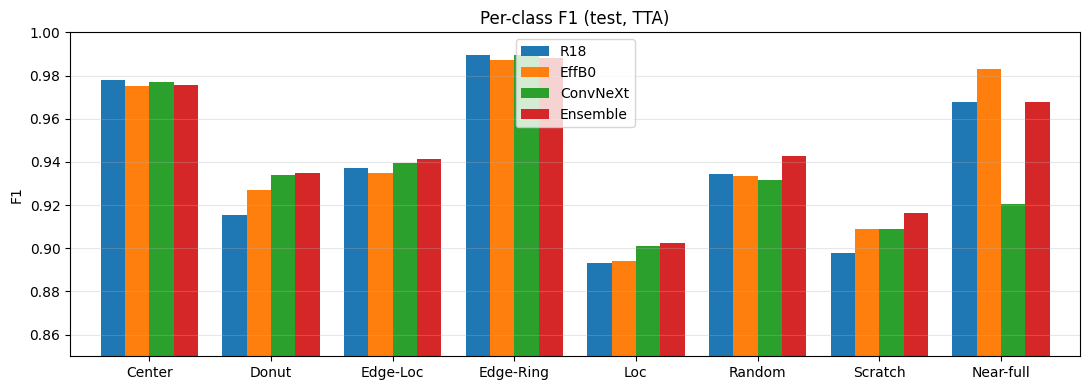

In [6]:
# 클래스별 F1: 개별 모델 vs 앙상블
per_cls = pd.DataFrame({SHORT[n]: f1_score(y_test, P_test[n].argmax(1), average=None) for n in CKPTS},
                       index=CLASS_NAMES)
per_cls["앙상블"] = f1_score(y_test, pred_ens, average=None)
print(per_cls.round(3))

ax = per_cls.rename(columns={"앙상블": "Ensemble"}).plot.bar(figsize=(11, 4), width=0.8)
ax.set_ylim(0.85, 1.0); ax.set_ylabel("F1"); ax.set_title("Per-class F1 (test, TTA)")
ax.grid(axis='y', alpha=.3); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

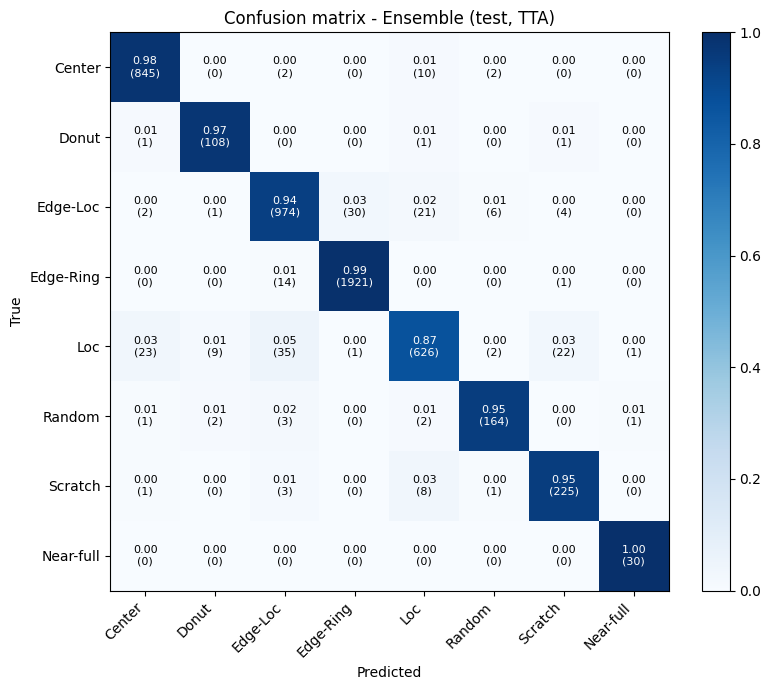

In [7]:
cm = confusion_matrix(y_test, pred_ens)
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cmn[i,j]:.2f}\n({cm[i,j]})", ha='center', va='center', fontsize=8,
                color='white' if cmn[i, j] > .5 else 'black')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix - Ensemble (test, TTA)")
plt.colorbar(im, fraction=.046); plt.tight_layout(); plt.show()

## 5. 모델끼리 얼마나 다르게 틀리나? (앙상블이 효과 있는 이유)

In [8]:
# 두 모델이 서로 다른 답을 낸 비율. 높을수록 서로 보완할 여지가 큼
names = list(CKPTS)
wrong = {n: P_test[n].argmax(1) != y_test for n in names}
for a, b in itertools.combinations(names, 2):
    both = (wrong[a] & wrong[b]).sum()
    only = (wrong[a] ^ wrong[b]).sum()
    print(f"{SHORT[a]:8s} vs {SHORT[b]:8s}: 둘 다 틀림 {both:3d} / 한쪽만 틀림 {only:3d}")
print(f"세 모델 모두 틀림: {(wrong[names[0]] & wrong[names[1]] & wrong[names[2]]).sum()}  "
      f"(앙상블로도 못 고치는 '진짜 어려운' 샘플)")

R18      vs EffB0   : 둘 다 틀림 161 / 한쪽만 틀림 134
R18      vs ConvNeXt: 둘 다 틀림 154 / 한쪽만 틀림 134
EffB0    vs ConvNeXt: 둘 다 틀림 153 / 한쪽만 틀림 140
세 모델 모두 틀림: 129  (앙상블로도 못 고치는 '진짜 어려운' 샘플)
